# LUAD33 — Local Ligand–Receptor Map Agreement (LIANA+)

**Paper figures**: Fig 5d,e (Supplementary Note S5)

The same analysis as for the dorsal tongue, applied to lung adenocarcinoma: does RNA transferred onto the protein
(PCF) section with SAME reproduce the local ligand–receptor (LR) patterns measured on the Xenium RNA section,
compared with a nearest same-celltype baseline?

**Dataset**: 59,999 Xenium metacells (template, 194 genes) and the 56,888 PCF metacells matched by SAME (query;
dp = 10, knn = 8, metacells of up to three cells). Cell types: B cell, Epithelial, Mesenchymal, Myeloid, T cell.

| Step | Setting |
|------|---------|
| SAME result | `results/dp10_knn8_MS3` with `results/mc_align.pkl`, `mc_ref.pkl` (paper run) |
| Units | metacells (≤ 3 cells); Xenium metacell RNA = mean of member cells' log-normalized expression |
| Baseline | nearest same-celltype metacell in the initial (VALIS) registration |
| LIANA+ | v1.7.3, bivariate local Moran's R, consensus resource, 100 permutations |
| Graph | binary Delaunay on native µm coordinates |
| Maps | Gaussian windows 25–100 µm, lattice spacing = window / 2, ≥ 2 summed kernel weight |
| Agreement | Spearman correlation vs RNA-only map, median over LR pairs |


## Workflow

1. **Two RNA reconstructions on the same protein-section cells.** Every SAME-matched protein-section metacell receives
   the RNA profile of one RNA-section metacell:
   * **SAME**: its SAME partner (the published dp = 10 run);
   * **Nearest same-celltype** (baseline): the closest RNA-section metacell of the same cell type in the initial,
     image-based registration, chosen independently for each metacell (RNA metacells can be reused).

   Both reconstructions use identical protein-section positions and differ only in the transferred RNA.
2. **Local LR scores with LIANA+.** Bivariate local Moran's R (consensus resource, binary Delaunay graph on native
   coordinates) is computed three times: on the RNA section with its measured RNA ("RNA-only"), and on the protein
   section with each transferred profile. Each run gives one score per metacell and LR pair.
3. **Smooth into maps.** For each run and LR pair, per-metacell scores are averaged with a Gaussian kernel (full width
   at half maximum 25, 50, 75 or 100 µm) on a common lattice in the initial shared registration. Lattice spacing is
   half the kernel width; kernels are truncated at 3σ; only lattice points with a summed kernel weight of at least 2
   in every map are kept.
4. **Compare maps.** Agreement with the RNA-only map is the Spearman correlation across lattice points, per LR pair,
   summarised as the median across LR pairs. No cell partners are used to define the reference scores.

LR pairs: those passing LIANA+'s default 5% expression filter in all three runs; the figures use the pairs with a
spatial pattern in the RNA section (RNA-only global Moran permutation p < 0.05, unadjusted). All expression-eligible
pairs are reported as a sensitivity analysis.


### Requirements

Run from `examples/luad/` after downloading the SAME data archive from Zenodo
(<https://zenodo.org/records/19056915>, see `examples/README.md`). Besides SAME's own requirements
(`pip install -r requirements.txt` at the repo root; needed to unpickle the MetaCell objects), this notebook uses
LIANA+ and scanpy. Versions used to produce the paper figures:

```bash
pip install -r requirements.txt "liana==1.7.3" "scanpy==1.11.4" "anndata==0.10.9" \
    "numpy==1.26.4" "scipy==1.16.2" "pandas==2.3.2" "matplotlib==3.10.6"
```

Runtime: about a minute on a laptop (three LIANA+ runs with 100 permutations each).


## Setup

In [1]:
import pickle
import sys
import warnings
from pathlib import Path

import anndata as ad
import liana as li
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy
from matplotlib.patches import Rectangle
from scipy.sparse import csr_matrix
from scipy.spatial import Delaunay, cKDTree
from scipy.stats import rankdata

warnings.filterwarnings('ignore', category=FutureWarning)

NOTEBOOK_DIR = Path('.').resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parents[1]
sys.path.insert(0, str(PROJECT_ROOT))  # SAME's `src` package (MetaCell class, needed to unpickle results)

DATA_DIR = NOTEBOOK_DIR / 'data'
RESULTS_DIR = NOTEBOOK_DIR / 'results'
FIG_DIR = NOTEBOOK_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'svg.fonttype': 'none', 'pdf.fonttype': 42, 'font.size': 8})

print(f'liana {li.__version__} | scanpy {sc.__version__} | anndata {ad.__version__} | '
      f'numpy {np.__version__} | scipy {scipy.__version__} | pandas {pd.__version__}')

liana 1.7.3 | scanpy 1.11.4 | anndata 0.10.9 | numpy 1.26.4 | scipy 1.16.2 | pandas 2.3.2


In [2]:
# analysis parameters (Supplementary Note S5)
WINDOWS_UM = (25, 50, 75, 100)  # Gaussian kernel full width at half maximum, µm
MIN_WEIGHT = 2.0                # minimum summed kernel weight per lattice point, in every map
ALPHA = 0.05                    # RNA-only global Moran permutation p-value for 'spatially patterned' LR pairs
N_PERMS, SEED = 100, 1337       # LIANA+ permutations and seed

SAME_COLOR, NN_COLOR = '#2B7FFF', '#FF2056'
INK, INK2, GRID = '#1f1f1f', '#5f6368', '#e6e6e3'
METHODS = ('SAME', 'Nearest same-celltype')

## Helper functions

The whole analysis is a few small functions: a Delaunay graph, a LIANA+ call, the nearest same-celltype baseline,
Gaussian map smoothing and a column-wise Spearman correlation.

In [3]:
def delaunay_graph(xy):
    """Binary, symmetric adjacency matrix of the Delaunay triangulation of points `xy` (n x 2)."""
    s = Delaunay(np.asarray(xy, float)).simplices
    i = np.concatenate([s[:, 0], s[:, 1], s[:, 0], s[:, 1], s[:, 2], s[:, 2]])
    j = np.concatenate([s[:, 1], s[:, 2], s[:, 2], s[:, 0], s[:, 1], s[:, 0]])
    adj = csr_matrix((np.ones(len(i)), (i, j)), shape=(len(xy), len(xy)))
    adj.data[:] = 1.0
    return adj


def liana_local(X, xy, genes, normalize):
    """LIANA+ bivariate local Moran's R for every consensus LR pair; returns an AnnData (units x LR pairs)
    with local scores in .X and global Moran's R / permutation p-values in .var."""
    adata = ad.AnnData(X=np.asarray(X, dtype=float), var=pd.DataFrame(index=list(genes)))
    if normalize:
        sc.pp.normalize_total(adata)
        sc.pp.log1p(adata)
    adata.obsp['spatial_connectivities'] = delaunay_graph(xy)
    return li.mt.bivariate(adata, local_name='morans', global_name='morans', use_raw=False,
                           resource_name='consensus', connectivity_key='spatial_connectivities',
                           n_perms=N_PERMS, seed=SEED, mask_negatives=False, verbose=False)


def nearest_same_celltype(query_xy, query_type, ref_xy, ref_type):
    """For each query unit, the index of the closest reference unit of the same cell type (reuse allowed)."""
    partner = np.full(len(query_xy), -1)
    for t in np.unique(query_type):
        q, r = np.where(query_type == t)[0], np.where(ref_type == t)[0]
        partner[q] = r[cKDTree(ref_xy[r]).query(query_xy[q], k=1)[1]]
    return partner


def units_per_um(native_xy, frame_xy):
    """Scale of the registration frame relative to native µm coordinates."""
    a, b = native_xy - native_xy.mean(0), frame_xy - frame_xy.mean(0)
    return float(np.sqrt((b ** 2).sum() / (a ** 2).sum()))


def make_lattice(lo, hi, window_um, scale):
    """Square lattice with spacing = half the window width, in registration-frame units."""
    step = window_um / 2 * scale
    xs, ys = np.arange(lo[0], hi[0], step), np.arange(lo[1], hi[1], step)
    gx, gy = np.meshgrid(xs, ys)
    return np.c_[gx.ravel(), gy.ravel()], gx.shape


def smooth(values, xy, lattice, sigma):
    """Gaussian-weighted mean of per-unit `values` (n x k) at each lattice point (truncated at 3 sigma);
    also returns the summed kernel weight per lattice point."""
    D = cKDTree(lattice).sparse_distance_matrix(cKDTree(xy), 3 * sigma, output_type='coo_matrix').tocsr()
    D.data = np.exp(-D.data ** 2 / (2 * sigma ** 2))
    weight = np.asarray(D.sum(1)).ravel()
    return (D @ values) / np.maximum(weight, 1e-12)[:, None], weight


def spearman_cols(A, B):
    """Spearman correlation between matching columns of A and B (ties averaged)."""
    A, B = rankdata(A, axis=0), rankdata(B, axis=0)
    A, B = A - A.mean(0), B - B.mean(0)
    return (A * B).sum(0) / np.sqrt((A * A).sum(0) * (B * B).sum(0))


def map_agreement(scores, rna_xy, prot_xy, scale, pairs):
    """Median Spearman agreement with the RNA-only map at each window width, plus per-pair correlations."""
    lo, hi = np.minimum(rna_xy.min(0), prot_xy.min(0)), np.maximum(rna_xy.max(0), prot_xy.max(0))
    rows, per_pair = [], {}
    for w in WINDOWS_UM:
        lattice, _ = make_lattice(lo, hi, w, scale)
        sigma = w / 2.355 * scale
        g, wg = smooth(scores['RNA-only'][:, pairs], rna_xy, lattice, sigma)
        s, ws = smooth(scores['SAME'][:, pairs], prot_xy, lattice, sigma)
        n, wn = smooth(scores['Nearest same-celltype'][:, pairs], prot_xy, lattice, sigma)
        ok = (wg >= MIN_WEIGHT) & (ws >= MIN_WEIGHT) & (wn >= MIN_WEIGHT)
        r_same, r_nn = spearman_cols(s[ok], g[ok]), spearman_cols(n[ok], g[ok])
        per_pair[w] = pd.DataFrame({'SAME': r_same, 'Nearest same-celltype': r_nn}, index=pairs)
        rows.append({'window_um': w, 'lattice_points': int(ok.sum()), 'LR_pairs': len(pairs),
                     'SAME': np.median(r_same), 'Nearest same-celltype': np.median(r_nn),
                     'difference': np.median(r_same) - np.median(r_nn),
                     'SAME_higher': f'{int((r_same > r_nn).sum())}/{len(pairs)}'})
    return pd.DataFrame(rows).set_index('window_um'), per_pair


def dense(adata):
    return adata.X.toarray() if hasattr(adata.X, 'toarray') else np.asarray(adata.X)

In [4]:
def plot_by_scale(table, title, fname):
    """Median agreement with the RNA-only LR maps at each window width."""
    fig, ax = plt.subplots(figsize=(3.6, 2.4))
    for col, color in zip(METHODS, (SAME_COLOR, NN_COLOR)):
        ax.plot(table.index, table[col], color=color, lw=1.4, label=col)
        ax.plot(table.index, table[col], 'o', ms=4.5, mfc=color, mec='white', mew=1.0)
    ax.set_xticks(WINDOWS_UM); ax.set_xlim(20, 105); ax.set_ylim(min(0.4, np.floor(table[list(METHODS)].min().min() * 10) / 10), 1.0)
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel('Map resolution (window width, µm)')
    ax.set_ylabel('Cell-cell communication agreement\n(median Spearman correlation)')
    ax.set_title(title, loc='left', fontsize=8)
    ax.legend(frameon=False, loc='upper left')
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    for ext in ('svg', 'png'):
        fig.savefig(FIG_DIR / f'{fname}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()


def plot_per_pair(per_pair, title, fname):
    """Agreement for each LR pair at one window width (dumbbell plot)."""
    p = per_pair.sort_values('SAME')
    y = np.arange(len(p))
    headroom = 1.6 if len(p) <= 8 else 0.0   # room for the legend above short lists
    fig, ax = plt.subplots(figsize=(3.8, 0.9 + 0.17 * (len(p) + headroom)))
    ax.hlines(y, p.min(1), p.max(1), color='#c9c9c6', lw=1.0, zorder=1)
    ax.plot(p['Nearest same-celltype'], y, 'o', ms=4.5, mfc=NN_COLOR, mec='white', mew=0.9, zorder=2, label='Nearest same-celltype')
    ax.plot(p['SAME'], y, 'o', ms=4.5, mfc=SAME_COLOR, mec='white', mew=0.9, zorder=3, label='SAME')
    ax.set_yticks(y); ax.set_yticklabels([s.replace('^', '–').replace('_', '/') for s in p.index], fontsize=7)
    ax.set_xlim(0, 1); ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0]); ax.set_ylim(-0.7, len(p) - 0.3 + headroom)
    ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel('Agreement at 50 µm (Spearman correlation)')
    ax.set_title(title, loc='left', fontsize=8)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], frameon=False, loc='upper left', handletextpad=0.2)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    for ext in ('svg', 'png'):
        fig.savefig(FIG_DIR / f'{fname}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()

## 1. Load metacells and Xenium expression

The MetaCell objects hold, for each metacell, its member cells, native coordinates (`Centroid_X`, `Centroid_Y`, µm)
and coordinates in the initial VALIS registration (`X`, `Y`). Member indices are row positions in the Xenium AnnData.

In [5]:
mc_align = pickle.load(open(RESULTS_DIR / 'mc_align.pkl', 'rb'))  # PCF metacells (query)
mc_ref = pickle.load(open(RESULTS_DIR / 'mc_ref.pkl', 'rb'))      # Xenium metacells (template)
xen = ad.read_h5ad(DATA_DIR / '0325_tsu33_annotated.h5ad')        # Xenium, log-normalized expression

A, R = mc_align.metacell_df, mc_ref.metacell_df
assert (A['metacell_id'].to_numpy() == np.arange(len(A))).all() and (R['metacell_id'].to_numpy() == np.arange(len(R))).all()
assert (mc_ref.original_df['Cell_Num'].astype(str).values == xen.obs['cell_id'].astype(str).values).all()

X = xen.X.toarray() if hasattr(xen.X, 'toarray') else np.asarray(xen.X)
rna_expr = np.vstack([X[list(m)].mean(0) for m in R['members']])   # metacell RNA = mean over member cells
genes = list(xen.var_names)
rna_type, prot_type_all = R['cell_type'].astype(str).to_numpy(), A['cell_type'].astype(str).to_numpy()
rna_native, rna_frame = R[['Centroid_X', 'Centroid_Y']].to_numpy(float), R[['X', 'Y']].to_numpy(float)
prot_native_all, prot_frame_all = A[['Centroid_X', 'Centroid_Y']].to_numpy(float), A[['X', 'Y']].to_numpy(float)
print(f'PCF metacells: {len(A)} | Xenium metacells: {len(R)} | genes: {len(genes)}')

PCF metacells: 58908 | Xenium metacells: 59999 | genes: 194


## 2. SAME partners and the nearest same-celltype baseline

Matches are read by metacell id (`Aligned_metacell_id` → `Ref_metacell_id`); `aligned_idx` / `ref_idx` are indices
within each sliding window. The match coordinates are checked against the metacell tables.

In [6]:
matches = pd.read_csv(RESULTS_DIR / 'dp10_knn8_MS3' / 'matchedDF.csv')
assert matches['Aligned_metacell_id'].is_unique
assert np.allclose(prot_frame_all[matches['Aligned_metacell_id']], matches[['X', 'Y']].to_numpy(float))
assert np.allclose(rna_frame[matches['Ref_metacell_id']], matches[['ref_X', 'ref_Y']].to_numpy(float))

same_partner = np.full(len(A), -1)
same_partner[matches['Aligned_metacell_id'].to_numpy()] = matches['Ref_metacell_id'].to_numpy()
units = np.where(same_partner >= 0)[0]          # every SAME-matched PCF metacell
p_type, p_native, p_frame = prot_type_all[units], prot_native_all[units], prot_frame_all[units]
partner = {'SAME': same_partner[units],
           'Nearest same-celltype': nearest_same_celltype(p_frame, p_type, rna_frame, rna_type)}
for m, j in partner.items():
    print(f'{m:22s}: {len(units)} PCF metacells | same cell type as partner {np.mean(rna_type[j] == p_type):.1%} | '
          f'distinct RNA partners {len(np.unique(j))}')

SAME                  : 56888 PCF metacells | same cell type as partner 67.1% | distinct RNA partners 45861
Nearest same-celltype : 56888 PCF metacells | same cell type as partner 100.0% | distinct RNA partners 28862


## 3. LIANA+ local LR scores

Three runs on the same 194 genes: the Xenium section with its own RNA, and the PCF section with RNA from SAME or from
the baseline. The two reconstructions share the PCF positions and Delaunay graph. (Expression is already
log-normalized, so it is not normalized again.) This step takes a few minutes.

In [7]:
runs = {'RNA-only': liana_local(rna_expr, rna_native, genes, normalize=False),
        'SAME': liana_local(rna_expr[partner['SAME']], p_native, genes, normalize=False),
        'Nearest same-celltype': liana_local(rna_expr[partner['Nearest same-celltype']], p_native, genes, normalize=False)}

pairs_all = runs['RNA-only'].var_names.intersection(runs['SAME'].var_names).intersection(runs['Nearest same-celltype'].var_names)
scores = {k: dense(v[:, pairs_all]) for k, v in runs.items()}
rna_stats = runs['RNA-only'].var.loc[pairs_all, ['ligand', 'receptor', 'morans', 'morans_pvals']]
pairs_sig = list(rna_stats.index[rna_stats['morans_pvals'] < ALPHA])
print(f'{len(pairs_all)} expression-eligible LR pairs; {len(pairs_sig)} with an RNA-only spatial pattern (p < {ALPHA})')
rna_stats.assign(used=rna_stats.index.isin(pairs_sig)).round(3)

5 expression-eligible LR pairs; 4 with an RNA-only spatial pattern (p < 0.05)


,ligand,receptor,morans,morans_pvals,used
interaction,,,,,
ICAM1^IL2RG,ICAM1,IL2RG,-0.033,0.00,True
SCGB3A2^MARCO,SCGB3A2,MARCO,-0.060,0.00,True
TGFB1^CAV1,TGFB1,CAV1,-0.002,0.19,False
ICAM1^CAV1,ICAM1,CAV1,-0.023,0.00,True
TNC^SDC4,TNC,SDC4,0.109,0.00,True


## 4. Map agreement across window widths

The scale of the VALIS frame relative to µm is estimated from the PCF metacells' native and registered coordinates.

In [8]:
scale = units_per_um(prot_native_all, prot_frame_all)
col = {p: i for i, p in enumerate(pairs_all)}
idx_sig, idx_all = [col[p] for p in pairs_sig], [col[p] for p in pairs_all]

table, per_pair = map_agreement(scores, rna_frame, p_frame, scale, idx_sig)
for w in per_pair: per_pair[w].index = pairs_sig
print(f'registration units per µm: {scale:.3f}')
table.round(3)

registration units per µm: 4.475


,lattice_points,LR_pairs,SAME,Nearest same-celltype,difference,SAME_higher
window_um,,,,,,
25,24676,4,0.647,0.456,0.191,4/4
50,31443,4,0.720,0.524,0.196,4/4
75,15473,4,0.798,0.585,0.212,4/4
100,9063,4,0.838,0.633,0.205,4/4


**Sensitivity**: all expression-eligible LR pairs, without the spatial-pattern filter.

In [9]:
table_all, _ = map_agreement(scores, rna_frame, p_frame, scale, idx_all)
table_all.round(3)

,lattice_points,LR_pairs,SAME,Nearest same-celltype,difference,SAME_higher
window_um,,,,,,
25,24676,5,0.630,0.430,0.201,5/5
50,31443,5,0.704,0.513,0.191,5/5
75,15473,5,0.788,0.578,0.210,5/5
100,9063,5,0.833,0.632,0.201,5/5


## 5. Figures

### Fig 5d — agreement by window width

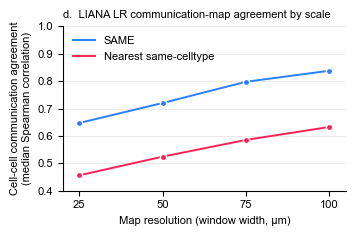

In [10]:
plot_by_scale(table, 'd.  LIANA LR communication-map agreement by scale', 'Fig5d_liana_agreement_by_scale')

### Fig 5e — agreement per LR pair at 50 µm

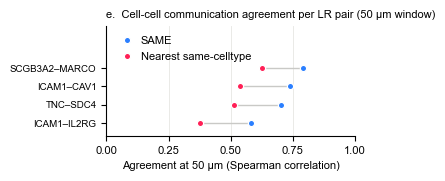

In [11]:
plot_per_pair(per_pair[50], 'e.  Cell-cell communication agreement per LR pair (50 µm window)', 'Fig5e_liana_agreement_per_pair')

## Summary

At 50 µm the median Spearman correlation with the Xenium-derived LR maps is about 0.72 for SAME and 0.52 for nearest
same-celltype assignment across the four spatially patterned LR pairs, with SAME higher for every pair and at all four
window widths. Including all five expression-eligible pairs gives 0.70 vs 0.51.